# Visualización de Datos - PEC 2

## Visualización 2 - Ridgeline Chart

### Descripción del conjunto de datos y objetivo

- Conjunto de datos: [Temperatura media diaria en España desde 2019 a 2025]https://open-meteo.com/en/docs/historical-weather-api?utm_source=chatgpt.com&latitude=40&longitude=-4&start_date=2019-01-01&end_date=2025-12-31&hourly=&daily=temperature_2m_mean)
- Objetivo: se pretende mostrar la evolución mensual de las temperaturas en España por día entre 2019 y 2025


### Lectura de los datos

In [6]:
import pandas as pd

# Las tres primeras líneas contienen metadatos de Open-Meteo.
df = pd.read_csv("open-meteo-39.96N4.02W512m.csv", skiprows=3, parse_dates=["time"])
df.head()

,time,temperature_2m_mean (°C)
0,2019-01-01,2.4
1,2019-01-02,2.4
2,2019-01-03,2.4
3,2019-01-04,3.0
4,2019-01-05,1.9


### Generación de la visualización tipo Ridgeline Chart

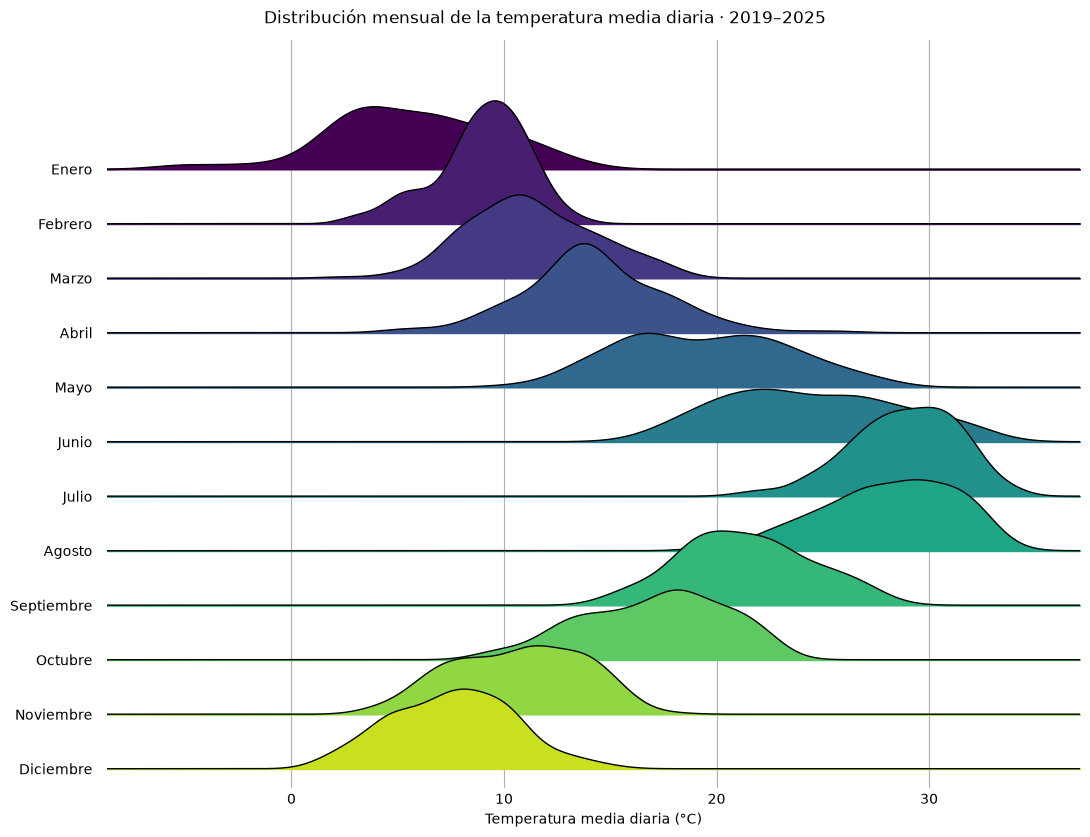

In [7]:
import joypy
import matplotlib.pyplot as plt

col_temperatura = "temperature_2m_mean (°C)"
meses = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre",
]

# Reunir las temperaturas diarias de 2019 a 2025, ambos incluidos.
datos = df.loc[
    df["time"].dt.year.between(2019, 2025),
    ["time", col_temperatura],
].copy()
datos[col_temperatura] = pd.to_numeric(datos[col_temperatura], errors="coerce")
datos = datos.dropna(subset=["time", col_temperatura])
datos["mes_numero"] = datos["time"].dt.month

# Agrupar por número de mes para mantener el orden de enero a diciembre.
grupos = datos.groupby("mes_numero", sort=True)
etiquetas = [meses[numero - 1] for numero in grupos.groups]

# Compatibilidad de JoyPy 0.2.6 con pandas 3: convertir los ejes en lista.
# La adaptación se aplica solo durante esta llamada, sin modificar la instalación.
from importlib import import_module

joypy_backend = import_module("joypy.joyplot")
flatten_original = joypy_backend._flatten
joypy_backend._flatten = lambda axes: list(flatten_original(axes))
try:
    fig, axes = joypy.joyplot(
        grupos,
        column=col_temperatura,
        labels=etiquetas,
        kind="kde",
        figsize=(11, 8),
        overlap=1.4,
        colormap=plt.cm.viridis,
        linewidth=1,
        grid="x",
        legend=False,
        x_range=[datos[col_temperatura].min() - 3, datos[col_temperatura].max() + 3],
    )
finally:
    joypy_backend._flatten = flatten_original

axes[-1].set_xlabel("Temperatura media diaria (°C)")
fig.suptitle("Distribución mensual de la temperatura media diaria · 2019–2025", y=1.02)
plt.show()
